# 🏠 House Prices — Modelado Avanzado + Ensemble

> **Kaggle Competition** | Chalito · LYONSOFT PERU
> Notebook final del pipeline: modelos avanzados, tuning con Optuna y ensemble.

---
### Posición en el pipeline
```
📓 01_EDA.ipynb                  ✅
📓 02_FeatureEngineering.ipynb   ✅  → X_train_FE.parquet
📓 03_Preprocessing_Final.ipynb  ✅  → X_train_scaled.npy / X_train_raw.npy
📓 04_Models.ipynb               ◀ ESTE NOTEBOOK
```

### Estructura
```
1.  Setup y carga de artefactos
2.  Modelos lineales (Ridge, Lasso, ElasticNet) — baseline refinado
3.  XGBoost — tuning con Optuna
4.  LightGBM — tuning con Optuna
5.  Gradient Boosting sklearn — modelo de diversidad
6.  Análisis de out-of-fold predictions (OOF)
7.  Stacking — meta-learner Ridge
8.  Blending optimizado — pesos con scipy
9.  Submission final
10. Resumen ejecutivo
```

In [1]:
# ─── 0. IMPORTACIONES ───────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
import joblib, os, time

# Sklearn
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Boosting
import xgboost  as xgb
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.35,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 12,
})
COLOR_MAIN    = '#2563EB'
COLOR_ACCENT  = '#F59E0B'
COLOR_DANGER  = '#EF4444'
COLOR_SUCCESS = '#10B981'
COLOR_PURPLE  = '#7C3AED'

pd.set_option('display.float_format', '{:.5f}'.format)

print('✅ Librerías cargadas')
print(f'   XGBoost  {xgb.__version__}')
print(f'   LightGBM {lgb.__version__}')
print(f'   Optuna   {optuna.__version__}')

✅ Librerías cargadas
   XGBoost  3.3.0
   LightGBM 4.6.0
   Optuna   4.9.0


---
## 1 · Carga de artefactos del preprocesamiento

In [2]:
# ─── 1.1 CARGAR DATASETS ────────────────────────────────────────────────────
# Versión A: escalada (modelos lineales)
X_train_scaled = np.load('X_train_scaled.npy')
X_test_scaled  = np.load('X_test_scaled.npy')

# Versión A reducida (Lasso selection)
X_train_lasso  = np.load('X_train_lasso.npy')
X_test_lasso   = np.load('X_test_lasso.npy')

# Versión B: sin escalar (tree-based)
X_train_raw    = np.load('X_train_raw.npy')
X_test_raw     = np.load('X_test_raw.npy')

# Target (log-space)
y              = pd.Series(np.load('y_train_log.npy'), name='SalePrice_log')

# Feature names y submission IDs
with open('feature_names_full.txt') as f:
    feature_names = f.read().splitlines()
with open('feature_names_lasso.txt') as f:
    feature_names_lasso = f.read().splitlines()

test_ids = pd.read_csv('test_ids.csv').squeeze()

print('─' * 55)
print(f'  X_train_scaled : {X_train_scaled.shape}   ← lineales')
print(f'  X_train_lasso  : {X_train_lasso.shape}   ← lineales (reducido)')
print(f'  X_train_raw    : {X_train_raw.shape}   ← tree-based')
print(f'  y              : {y.shape}')
print(f'  Feature names  : {len(feature_names)}')
print(f'  Test IDs       : {len(test_ids)}')
print('─' * 55)
print(f'  Target → media={y.mean():.4f}  std={y.std():.4f}  skew={y.skew():.4f}')

───────────────────────────────────────────────────────
  X_train_scaled : (1456, 288)   ← lineales
  X_train_lasso  : (1456, 126)   ← lineales (reducido)
  X_train_raw    : (1456, 288)   ← tree-based
  y              : (1456,)
  Feature names  : 288
  Test IDs       : 1459
───────────────────────────────────────────────────────
  Target → media=12.0219  std=0.3961  skew=0.0655


---
## 2 · Utilidades de evaluación y registro

In [3]:
# ─── 2.1 FUNCIÓN RMSLE CV + REGISTRO CENTRALIZADO ───────────────────────────
N_FOLDS = 10
KF = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

# Registro global de resultados
model_scores = {}   # {nombre: {'mean': float, 'std': float}}
oof_preds    = {}   # {nombre: array OOF de longitud ntrain}
test_preds   = {}   # {nombre: array predicciones en test}

def rmsle_cv(model, X, y, label, verbose=True):
    """Evalúa con K-Fold CV. y está en log-space → RMSE = RMSLE."""
    t0 = time.time()
    scores = np.sqrt(-cross_val_score(
        model, X, y,
        scoring='neg_mean_squared_error',
        cv=KF, n_jobs=-1
    ))
    elapsed = time.time() - t0
    model_scores[label] = {'mean': scores.mean(), 'std': scores.std()}
    if verbose:
        print(f'  {label:<42}  RMSLE = {scores.mean():.5f} ± {scores.std():.5f}  ({elapsed:.1f}s)')
    return scores

def get_oof_and_test(model, X_tr, X_te, y, label):
    """Genera OOF predictions y predicciones en test (promedio de folds)."""
    n_train = len(y)
    n_test  = X_te.shape[0]
    oof  = np.zeros(n_train)
    test_fold_preds = np.zeros((N_FOLDS, n_test))

    for fold_i, (tr_idx, val_idx) in enumerate(KF.split(X_tr)):
        model.fit(X_tr[tr_idx] if isinstance(X_tr, np.ndarray) else X_tr.iloc[tr_idx],
                  y.iloc[tr_idx])
        oof[val_idx] = model.predict(
            X_tr[val_idx] if isinstance(X_tr, np.ndarray) else X_tr.iloc[val_idx])
        test_fold_preds[fold_i] = model.predict(X_te)

    rmsle = np.sqrt(mean_squared_error(y, oof))
    test_mean = test_fold_preds.mean(axis=0)

    oof_preds[label]  = oof
    test_preds[label] = test_mean
    model_scores[label] = {'mean': rmsle, 'std': 0}
    print(f'  {label:<42}  OOF RMSLE = {rmsle:.5f}')
    return oof, test_mean

print('✅ Utilidades listas')
print(f'   K-Folds: {N_FOLDS}  |  random_state=42')

✅ Utilidades listas
   K-Folds: 10  |  random_state=42


---
## 3 · Modelos Lineales — Baseline refinado
> Ridge, Lasso y ElasticNet con los hiperparámetros afinados manualmente.
> Son la columna vertebral del ensemble final: estables y bien calibrados.

In [4]:
# ─── 3.1 GRID MANUAL PARA LINEALES ─────────────────────────────────────────
print('MODELOS LINEALES (10-fold CV)')
print('─' * 60)

# Ridge — buscar el mejor alpha
ridge_alphas = [5, 10, 15, 20, 30, 50]
ridge_results = {}
for alpha in ridge_alphas:
    sc = rmsle_cv(Ridge(alpha=alpha), X_train_scaled, y,
                  label=f'Ridge α={alpha}', verbose=False)
    ridge_results[alpha] = sc.mean()

best_ridge_alpha = min(ridge_results, key=ridge_results.get)
print(f'  Ridge  → mejor α={best_ridge_alpha}  RMSLE={ridge_results[best_ridge_alpha]:.5f}')

# Lasso
lasso_alphas = [0.0001, 0.0003, 0.0005, 0.001]
lasso_results = {}
for alpha in lasso_alphas:
    sc = rmsle_cv(Lasso(alpha=alpha, max_iter=15000), X_train_scaled, y,
                  label=f'Lasso α={alpha}', verbose=False)
    lasso_results[alpha] = sc.mean()

best_lasso_alpha = min(lasso_results, key=lasso_results.get)
print(f'  Lasso  → mejor α={best_lasso_alpha}  RMSLE={lasso_results[best_lasso_alpha]:.5f}')

# ElasticNet
enet_configs = [(0.0003, 0.8), (0.0005, 0.8), (0.0005, 0.9), (0.001, 0.7)]
enet_results = {}
for alpha, l1 in enet_configs:
    sc = rmsle_cv(ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=15000),
                  X_train_scaled, y, label=f'ENet α={alpha} l1={l1}', verbose=False)
    enet_results[(alpha, l1)] = sc.mean()

best_enet = min(enet_results, key=enet_results.get)
print(f'  ENet   → mejor α={best_enet[0]} l1={best_enet[1]}  RMSLE={enet_results[best_enet]:.5f}')
print('─' * 60)

MODELOS LINEALES (10-fold CV)
────────────────────────────────────────────────────────────
  Ridge  → mejor α=10  RMSLE=0.11010
  Lasso  → mejor α=0.0003  RMSLE=0.10926
  ENet   → mejor α=0.0003 l1=0.8  RMSLE=0.10919
────────────────────────────────────────────────────────────


In [5]:
# ─── 3.2 OOF PREDICTIONS — LINEALES ────────────────────────────────────────
print('\nGenerando OOF predictions para lineales...')

ridge_model = Ridge(alpha=best_ridge_alpha)
lasso_model = Lasso(alpha=best_lasso_alpha, max_iter=15000)
enet_model  = ElasticNet(alpha=best_enet[0], l1_ratio=best_enet[1], max_iter=15000)

oof_ridge, test_ridge = get_oof_and_test(ridge_model, X_train_scaled, X_test_scaled, y, 'Ridge')
oof_lasso, test_lasso = get_oof_and_test(lasso_model, X_train_scaled, X_test_scaled, y, 'Lasso')
oof_enet,  test_enet  = get_oof_and_test(enet_model,  X_train_scaled, X_test_scaled, y, 'ElasticNet')


Generando OOF predictions para lineales...
  Ridge                                       OOF RMSLE = 0.11088
  Lasso                                       OOF RMSLE = 0.10999
  ElasticNet                                  OOF RMSLE = 0.10992


---
## 4 · XGBoost — Tuning con Optuna
> Búsqueda bayesiana de hiperparámetros. Mucho más eficiente que GridSearch.
> Usamos los OOF del training set como métrica de optimización.

In [6]:
# ─── 4.1 OBJETIVO OPTUNA PARA XGBOOST ──────────────────────────────────────
def xgb_objective(trial):
    params = {
        'n_estimators'      : trial.suggest_int('n_estimators', 500, 3000, step=100),
        'max_depth'         : trial.suggest_int('max_depth', 3, 7),
        'learning_rate'     : trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        'min_child_weight'  : trial.suggest_int('min_child_weight', 1, 7),
        'subsample'         : trial.suggest_float('subsample', 0.5, 0.9),
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.4, 0.9),
        'colsample_bylevel' : trial.suggest_float('colsample_bylevel', 0.4, 0.9),
        'reg_alpha'         : trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda'        : trial.suggest_float('reg_lambda', 1e-4, 1.0, log=True),
        'gamma'             : trial.suggest_float('gamma', 0.0, 0.5),
        'random_state'      : 42,
        'n_jobs'            : -1,
        'verbosity'         : 0,
        'tree_method'       : 'hist',
    }
    model = xgb.XGBRegressor(**params)
    scores = np.sqrt(-cross_val_score(
        model, X_train_raw, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1
    ))
    return scores.mean()

print('🔍 Optimizando XGBoost con Optuna (50 trials, 5-fold)...')
print('   (puede tardar 3-6 minutos)')
t0 = time.time()

study_xgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(xgb_objective, n_trials=50, show_progress_bar=True)

elapsed = time.time() - t0
print(f'\n✅ Optimización XGBoost completada en {elapsed/60:.1f} min')
print(f'   Mejor RMSLE (5-fold): {study_xgb.best_value:.5f}')
print(f'   Mejores parámetros:')
for k, v in study_xgb.best_params.items():
    print(f'     {k:<22}: {v}')

🔍 Optimizando XGBoost con Optuna (50 trials, 5-fold)...
   (puede tardar 3-6 minutos)


Best trial: 31. Best value: 0.113941: 100%|██████████| 50/50 [08:20<00:00, 10.00s/it]


✅ Optimización XGBoost completada en 8.3 min
   Mejor RMSLE (5-fold): 0.11394
   Mejores parámetros:
     n_estimators          : 2300
     max_depth             : 3
     learning_rate         : 0.01034775039306223
     min_child_weight      : 4
     subsample             : 0.5246719922363831
     colsample_bytree      : 0.7695385548124559
     colsample_bylevel     : 0.5225658394072078
     reg_alpha             : 0.02516509182316484
     reg_lambda            : 0.08755958615184518
     gamma                 : 0.021683668489873756


Generando OOF predictions XGBoost (10-fold)...
  XGBoost                                     OOF RMSLE = 0.11086


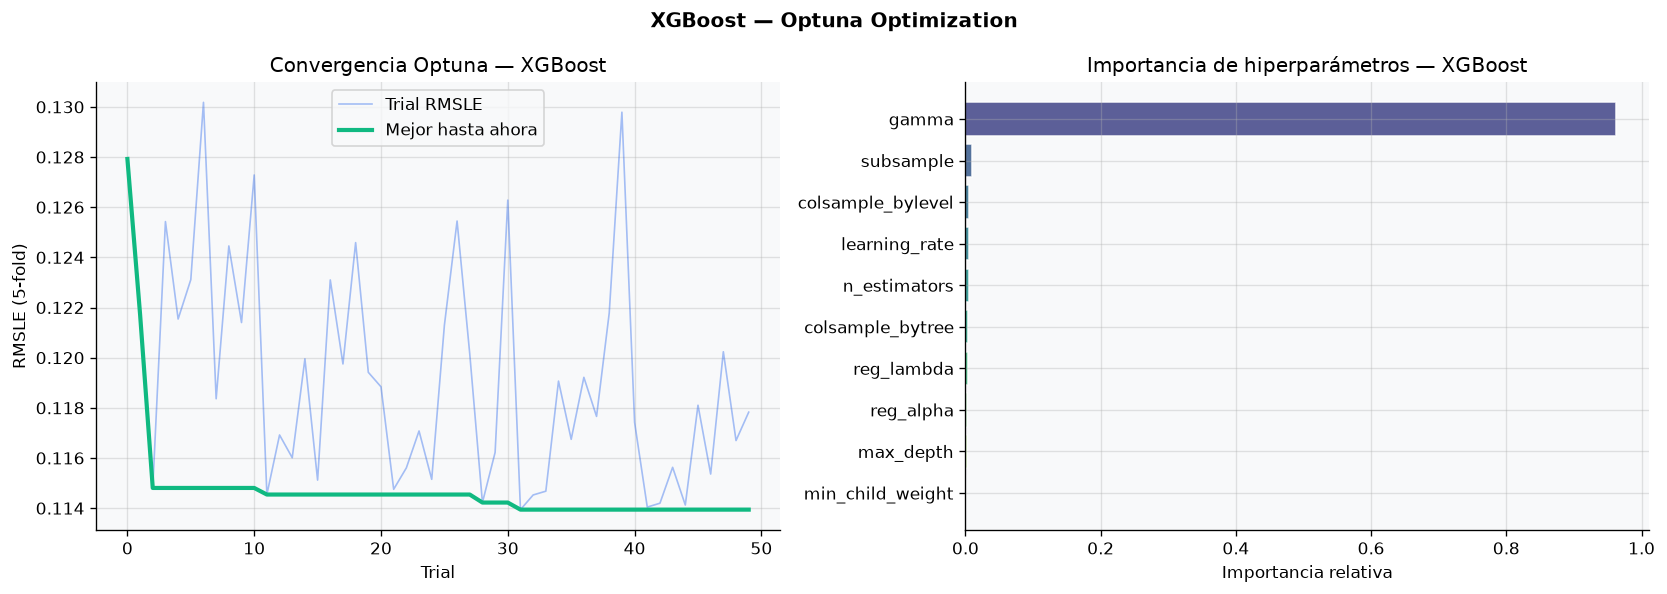

In [7]:
# ─── 4.2 MODELO XGB FINAL + OOF ────────────────────────────────────────────
best_xgb_params = study_xgb.best_params.copy()
best_xgb_params.update({'random_state': 42, 'n_jobs': -1, 'verbosity': 0, 'tree_method': 'hist'})

xgb_model = xgb.XGBRegressor(**best_xgb_params)

print('Generando OOF predictions XGBoost (10-fold)...')
oof_xgb, test_xgb = get_oof_and_test(xgb_model, X_train_raw, X_test_raw, y, 'XGBoost')

# Curva de optimización Optuna
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('XGBoost — Optuna Optimization', fontweight='bold')

# Curva de convergencia
ax = axes[0]
trial_values = [t.value for t in study_xgb.trials if t.value is not None]
best_so_far  = np.minimum.accumulate(trial_values)
ax.plot(trial_values, color=COLOR_MAIN, alpha=0.4, linewidth=1, label='Trial RMSLE')
ax.plot(best_so_far,  color=COLOR_SUCCESS, linewidth=2.5, label='Mejor hasta ahora')
ax.set_xlabel('Trial'); ax.set_ylabel('RMSLE (5-fold)')
ax.set_title('Convergencia Optuna — XGBoost')
ax.legend()

# Importancia de hiperparámetros
ax = axes[1]
importances = optuna.importance.get_param_importances(study_xgb)
params_imp  = list(importances.keys())
values_imp  = list(importances.values())
clrs = plt.cm.viridis(np.linspace(0.2, 0.9, len(params_imp)))
ax.barh(params_imp[::-1], values_imp[::-1], color=clrs[::-1], alpha=0.85, edgecolor='white')
ax.set_xlabel('Importancia relativa')
ax.set_title('Importancia de hiperparámetros — XGBoost')

plt.tight_layout()
plt.savefig('model_01_xgb_optuna.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 5 · LightGBM — Tuning con Optuna
> LightGBM suele superar a XGBoost en velocidad y en ocasiones también en score.
> Usar ambos en el ensemble aprovecha su correlación imperfecta.

In [8]:
# ─── 5.1 OBJETIVO OPTUNA PARA LIGHTGBM ─────────────────────────────────────
def lgb_objective(trial):
    params = {
        'n_estimators'      : trial.suggest_int('n_estimators', 500, 3000, step=100),
        'max_depth'         : trial.suggest_int('max_depth', 3, 8),
        'num_leaves'        : trial.suggest_int('num_leaves', 20, 150),
        'learning_rate'     : trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        'min_child_samples' : trial.suggest_int('min_child_samples', 10, 60),
        'subsample'         : trial.suggest_float('subsample', 0.5, 0.95),
        'subsample_freq'    : 1,
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.4, 0.95),
        'reg_alpha'         : trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda'        : trial.suggest_float('reg_lambda', 1e-4, 1.0, log=True),
        'min_split_gain'    : trial.suggest_float('min_split_gain', 0.0, 0.3),
        'random_state'      : 42,
        'n_jobs'            : -1,
        'verbose'           : -1,
    }
    model = lgb.LGBMRegressor(**params)
    scores = np.sqrt(-cross_val_score(
        model, X_train_raw, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1
    ))
    return scores.mean()

print('🔍 Optimizando LightGBM con Optuna (50 trials, 5-fold)...')
print('   (puede tardar 2-4 minutos)')
t0 = time.time()

study_lgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study_lgb.optimize(lgb_objective, n_trials=50, show_progress_bar=True)

elapsed = time.time() - t0
print(f'\n✅ Optimización LightGBM completada en {elapsed/60:.1f} min')
print(f'   Mejor RMSLE (5-fold): {study_lgb.best_value:.5f}')
print(f'   Mejores parámetros:')
for k, v in study_lgb.best_params.items():
    print(f'     {k:<22}: {v}')

🔍 Optimizando LightGBM con Optuna (50 trials, 5-fold)...
   (puede tardar 2-4 minutos)


Best trial: 35. Best value: 0.114838: 100%|██████████| 50/50 [04:24<00:00,  5.29s/it]


✅ Optimización LightGBM completada en 4.4 min
   Mejor RMSLE (5-fold): 0.11484
   Mejores parámetros:
     n_estimators          : 700
     max_depth             : 3
     num_leaves            : 66
     learning_rate         : 0.020046612574667756
     min_child_samples     : 13
     subsample             : 0.5839391834640252
     colsample_bytree      : 0.5532276200395972
     reg_alpha             : 0.019951447930203613
     reg_lambda            : 0.005784831028835708
     min_split_gain        : 0.0212793873171555


Generando OOF predictions LightGBM (10-fold)...
  LightGBM                                    OOF RMSLE = 0.11444


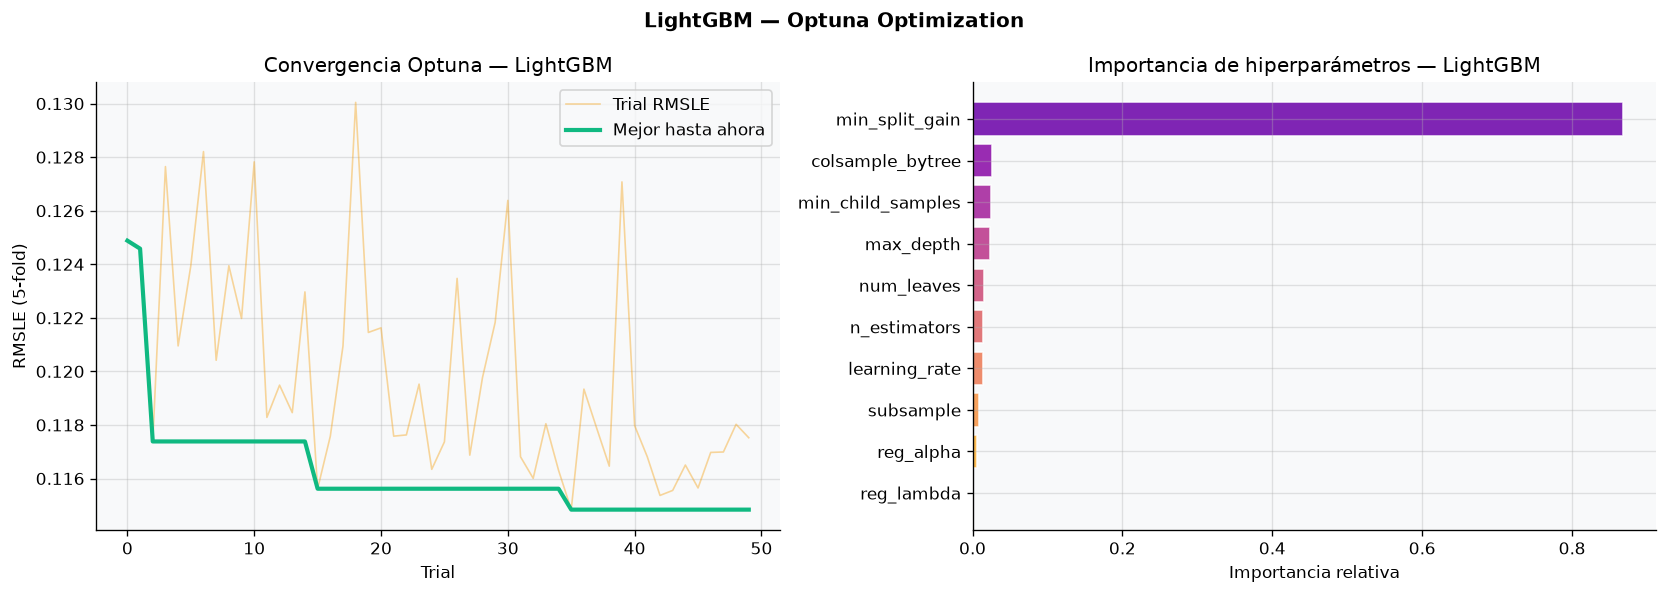

In [9]:
# ─── 5.2 MODELO LGB FINAL + OOF ────────────────────────────────────────────
best_lgb_params = study_lgb.best_params.copy()
best_lgb_params.update({'random_state': 42, 'n_jobs': -1, 'verbose': -1, 'subsample_freq': 1})

lgb_model = lgb.LGBMRegressor(**best_lgb_params)

print('Generando OOF predictions LightGBM (10-fold)...')
oof_lgb, test_lgb = get_oof_and_test(lgb_model, X_train_raw, X_test_raw, y, 'LightGBM')

# Curva de optimización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('LightGBM — Optuna Optimization', fontweight='bold')

ax = axes[0]
trial_values_lgb = [t.value for t in study_lgb.trials if t.value is not None]
best_so_far_lgb  = np.minimum.accumulate(trial_values_lgb)
ax.plot(trial_values_lgb, color=COLOR_ACCENT, alpha=0.4, linewidth=1, label='Trial RMSLE')
ax.plot(best_so_far_lgb,  color=COLOR_SUCCESS, linewidth=2.5, label='Mejor hasta ahora')
ax.set_xlabel('Trial'); ax.set_ylabel('RMSLE (5-fold)')
ax.set_title('Convergencia Optuna — LightGBM')
ax.legend()

ax = axes[1]
importances_lgb = optuna.importance.get_param_importances(study_lgb)
p_lgb = list(importances_lgb.keys())
v_lgb = list(importances_lgb.values())
clrs2 = plt.cm.plasma(np.linspace(0.2, 0.9, len(p_lgb)))
ax.barh(p_lgb[::-1], v_lgb[::-1], color=clrs2[::-1], alpha=0.85, edgecolor='white')
ax.set_xlabel('Importancia relativa')
ax.set_title('Importancia de hiperparámetros — LightGBM')

plt.tight_layout()
plt.savefig('model_02_lgb_optuna.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 6 · Gradient Boosting sklearn — Modelo de diversidad
> Distinto algoritmo al de XGB/LGB → correlación baja con ellos → mejora el ensemble.

In [10]:
# ─── 6.1 GRADIENT BOOSTING (GBR sklearn) ────────────────────────────────────
def gbr_objective(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 1000, 3000, step=200),
        'max_depth'       : trial.suggest_int('max_depth', 3, 5),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_features'    : trial.suggest_float('max_features', 0.3, 0.8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 20),
        'subsample'       : trial.suggest_float('subsample', 0.6, 0.9),
        'random_state'    : 42,
    }
    model = GradientBoostingRegressor(**params)
    scores = np.sqrt(-cross_val_score(
        model, X_train_raw, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=1
    ))
    return scores.mean()

print('🔍 Optimizando GradientBoosting con Optuna (30 trials)...')
t0 = time.time()
study_gbr = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study_gbr.optimize(gbr_objective, n_trials=30, show_progress_bar=True)
elapsed = time.time() - t0
print(f'\n✅ GBR completado en {elapsed/60:.1f} min  — RMSLE={study_gbr.best_value:.5f}')

gbr_model = GradientBoostingRegressor(**study_gbr.best_params, random_state=42)
print('\nGenerando OOF predictions GBR (10-fold)...')
oof_gbr, test_gbr = get_oof_and_test(gbr_model, X_train_raw, X_test_raw, y, 'GBR_sklearn')

🔍 Optimizando GradientBoosting con Optuna (30 trials)...


Best trial: 24. Best value: 0.113252: 100%|██████████| 30/30 [50:16<00:00, 100.55s/it]



✅ GBR completado en 50.3 min  — RMSLE=0.11325

Generando OOF predictions GBR (10-fold)...
  GBR_sklearn                                 OOF RMSLE = 0.11035


---
## 7 · Análisis de Out-of-Fold Predictions
> Comparamos los errores de cada modelo y su correlación entre sí.
> Correlación baja entre modelos → ensemble más poderoso.

In [11]:
# ─── 7.1 TABLA DE RESULTADOS ────────────────────────────────────────────────
results_df = pd.DataFrame([
    {'Modelo': k, 'OOF_RMSLE': v['mean']}
    for k, v in model_scores.items()
]).sort_values('OOF_RMSLE')

print('\n📊 RANKING DE MODELOS (OOF RMSLE — menor = mejor):')
print('─' * 50)
display(results_df.reset_index(drop=True).style
        .background_gradient(cmap='RdYlGn_r', subset=['OOF_RMSLE'])
        .format({'OOF_RMSLE': '{:.5f}'})
        .hide(axis='index'))


📊 RANKING DE MODELOS (OOF RMSLE — menor = mejor):
──────────────────────────────────────────────────


Modelo,OOF_RMSLE
ENet α=0.0003 l1=0.8,0.10919
Lasso α=0.0003,0.10926
ENet α=0.0005 l1=0.8,0.10948
ENet α=0.0005 l1=0.9,0.10964
Lasso α=0.0005,0.10985
ElasticNet,0.10992
Lasso,0.10999
Ridge α=10,0.11010
Lasso α=0.0001,0.11015
Ridge α=5,0.11022


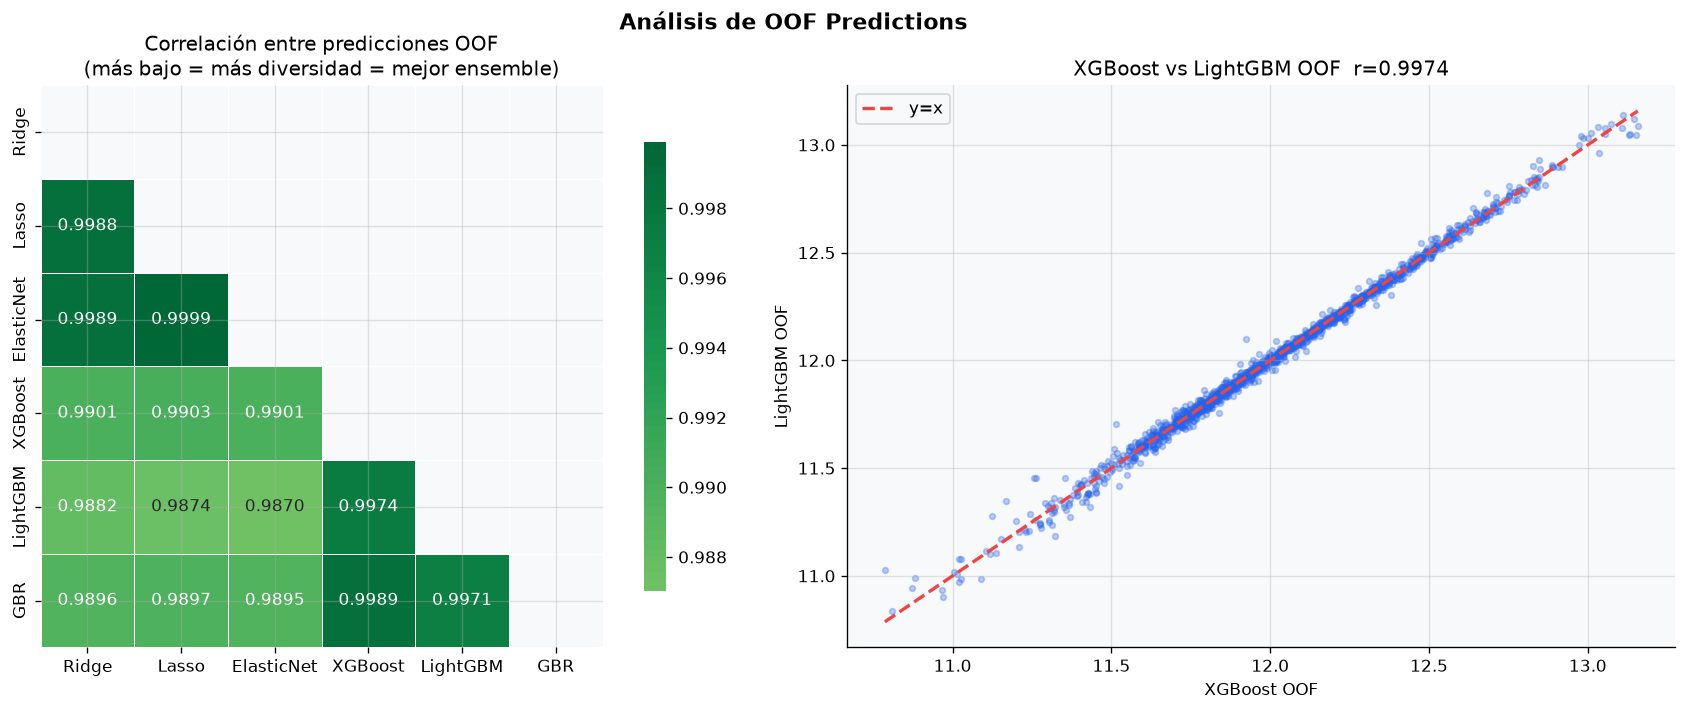


💡 Correlaciones entre modelos (ideal: < 0.999 para diversidad):
   Ridge        ↔ Lasso         r = 0.99885
   Ridge        ↔ ElasticNet    r = 0.99887
   Ridge        ↔ GBR           r = 0.98956
   XGBoost      ↔ Lasso         r = 0.99027
   XGBoost      ↔ ElasticNet    r = 0.99006
   XGBoost      ↔ GBR           r = 0.99893
   LightGBM     ↔ Lasso         r = 0.98738
   LightGBM     ↔ ElasticNet    r = 0.98702
   LightGBM     ↔ GBR           r = 0.99709


In [12]:
# ─── 7.2 CORRELACIÓN ENTRE MODELOS (OOF) ───────────────────────────────────
oof_df = pd.DataFrame({
    'Ridge'      : oof_ridge,
    'Lasso'      : oof_lasso,
    'ElasticNet' : oof_enet,
    'XGBoost'    : oof_xgb,
    'LightGBM'   : oof_lgb,
    'GBR'        : oof_gbr,
})

corr_matrix = oof_df.corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Análisis de OOF Predictions', fontweight='bold', fontsize=13)

# Heatmap correlación
ax = axes[0]
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.4f',
            cmap='RdYlGn', center=0.97, square=True,
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 10})
ax.set_title('Correlación entre predicciones OOF\n(más bajo = más diversidad = mejor ensemble)')

# Scatter: XGBoost vs LightGBM OOF
ax = axes[1]
ax.scatter(oof_xgb, oof_lgb, alpha=0.3, s=12, color=COLOR_MAIN)
ax.plot([oof_xgb.min(), oof_xgb.max()],
        [oof_xgb.min(), oof_xgb.max()],
        color=COLOR_DANGER, linewidth=2, linestyle='--', label='y=x')
r_xl = corr_matrix.loc['XGBoost','LightGBM']
ax.set_xlabel('XGBoost OOF'); ax.set_ylabel('LightGBM OOF')
ax.set_title(f'XGBoost vs LightGBM OOF  r={r_xl:.4f}')
ax.legend()

plt.tight_layout()
plt.savefig('model_03_oof_analysis.png', bbox_inches='tight', dpi=120)
plt.show()

print('\n💡 Correlaciones entre modelos (ideal: < 0.999 para diversidad):')
for m1 in ['Ridge','XGBoost','LightGBM']:
    for m2 in ['Lasso','ElasticNet','GBR']:
        if m1 != m2:
            r = corr_matrix.loc[m1, m2]
            print(f'   {m1:<12} ↔ {m2:<12}  r = {r:.5f}')

---
## 8 · Stacking — Meta-learner Ridge
> El stacking usa las predicciones OOF de los modelos base como features del meta-modelo.
> El meta-learner aprende el peso óptimo de cada modelo en cada región del espacio.

In [13]:
# ─── 8.1 CONSTRUIR META-FEATURES ───────────────────────────────────────────
# Meta-features de entrenamiento = OOF predictions de cada modelo base
meta_train = np.column_stack([oof_ridge, oof_lasso, oof_enet,
                               oof_xgb, oof_lgb, oof_gbr])
meta_test  = np.column_stack([test_ridge, test_lasso, test_enet,
                               test_xgb, test_lgb, test_gbr])

meta_feature_names = ['Ridge','Lasso','ElasticNet','XGBoost','LightGBM','GBR']

print(f'Meta-features train : {meta_train.shape}')
print(f'Meta-features test  : {meta_test.shape}')

# ─── 8.2 META-LEARNER: RIDGE ────────────────────────────────────────────────
# Buscar el mejor alpha para el meta-learner
meta_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
meta_scores = {}
for alpha in meta_alphas:
    sc = np.sqrt(-cross_val_score(
        Ridge(alpha=alpha), meta_train, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=10, shuffle=True, random_state=42)
    ))
    meta_scores[alpha] = sc.mean()

best_meta_alpha = min(meta_scores, key=meta_scores.get)
stacking_rmsle  = meta_scores[best_meta_alpha]

print(f'\nMeta-learner Ridge óptimo: α={best_meta_alpha}')
print(f'Stacking RMSLE (10-fold): {stacking_rmsle:.5f}')

# Entrenar meta-learner en todos los datos
meta_ridge = Ridge(alpha=best_meta_alpha)
meta_ridge.fit(meta_train, y)
stack_test_pred = meta_ridge.predict(meta_test)

# Coeficientes del meta-learner
meta_coef_df = pd.DataFrame({
    'Modelo': meta_feature_names,
    'Peso': meta_ridge.coef_
}).sort_values('Peso', ascending=False)

print('\n📊 Pesos aprendidos por el meta-learner:')
print(meta_coef_df.to_string(index=False))
model_scores['Stacking_Ridge'] = {'mean': stacking_rmsle, 'std': 0}

Meta-features train : (1456, 6)
Meta-features test  : (1459, 6)

Meta-learner Ridge óptimo: α=5.0
Stacking RMSLE (10-fold): 0.10664

📊 Pesos aprendidos por el meta-learner:
    Modelo    Peso
       GBR 0.19317
ElasticNet 0.18555
     Lasso 0.17808
   XGBoost 0.16405
     Ridge 0.15697
  LightGBM 0.12362


---
## 9 · Blending optimizado — Pesos con scipy
> Alternativa al stacking: promedio ponderado con pesos optimizados numéricamente.
> Más simple, más interpretable, y a veces compite con el stacking.

In [14]:
# ─── 9.1 OPTIMIZAR PESOS DEL BLEND ─────────────────────────────────────────
def rmsle_blend(weights, oof_matrix, y_true):
    """RMSLE del blend ponderado de OOF predictions."""
    weights = np.array(weights)
    weights = np.abs(weights) / np.abs(weights).sum()  # normalizar a suma=1
    blend   = oof_matrix @ weights
    return np.sqrt(mean_squared_error(y_true, blend))

# Punto de inicio: pesos iguales
n_models  = meta_train.shape[1]
w0        = np.ones(n_models) / n_models
bounds    = [(0.0, 1.0)] * n_models

result = minimize(
    rmsle_blend,
    w0,
    args=(meta_train, y.values),
    method='SLSQP',
    bounds=bounds,
    options={'maxiter': 2000, 'ftol': 1e-10}
)

# Normalizar pesos finales
opt_weights = np.abs(result.x) / np.abs(result.x).sum()
blend_oof   = meta_train @ opt_weights
blend_rmsle = np.sqrt(mean_squared_error(y.values, blend_oof))
blend_test  = meta_test @ opt_weights

print('📊 PESOS OPTIMIZADOS DEL BLEND:')
print('─' * 45)
for name, weight in zip(meta_feature_names, opt_weights):
    bar = '█' * int(weight * 40)
    print(f'  {name:<12} {weight:.4f}  {bar}')
print('─' * 45)
print(f'  Blend OOF RMSLE: {blend_rmsle:.5f}')
model_scores['Blend_optimizado'] = {'mean': blend_rmsle, 'std': 0}

# Comparar stacking vs blending vs mejores individuales
print(f'\n  Mejor individual (LGB): {model_scores.get("LightGBM", {}).get("mean", 0):.5f}')
print(f'  Stacking Ridge:          {stacking_rmsle:.5f}')
print(f'  Blending optimizado:     {blend_rmsle:.5f}')

📊 PESOS OPTIMIZADOS DEL BLEND:
─────────────────────────────────────────────
  Ridge        0.0000  
  Lasso        0.0000  
  ElasticNet   0.5156  ████████████████████
  XGBoost      0.0000  
  LightGBM     0.0000  
  GBR          0.4844  ███████████████████
─────────────────────────────────────────────
  Blend OOF RMSLE: 0.10660

  Mejor individual (LGB): 0.11444
  Stacking Ridge:          0.10664
  Blending optimizado:     0.10660


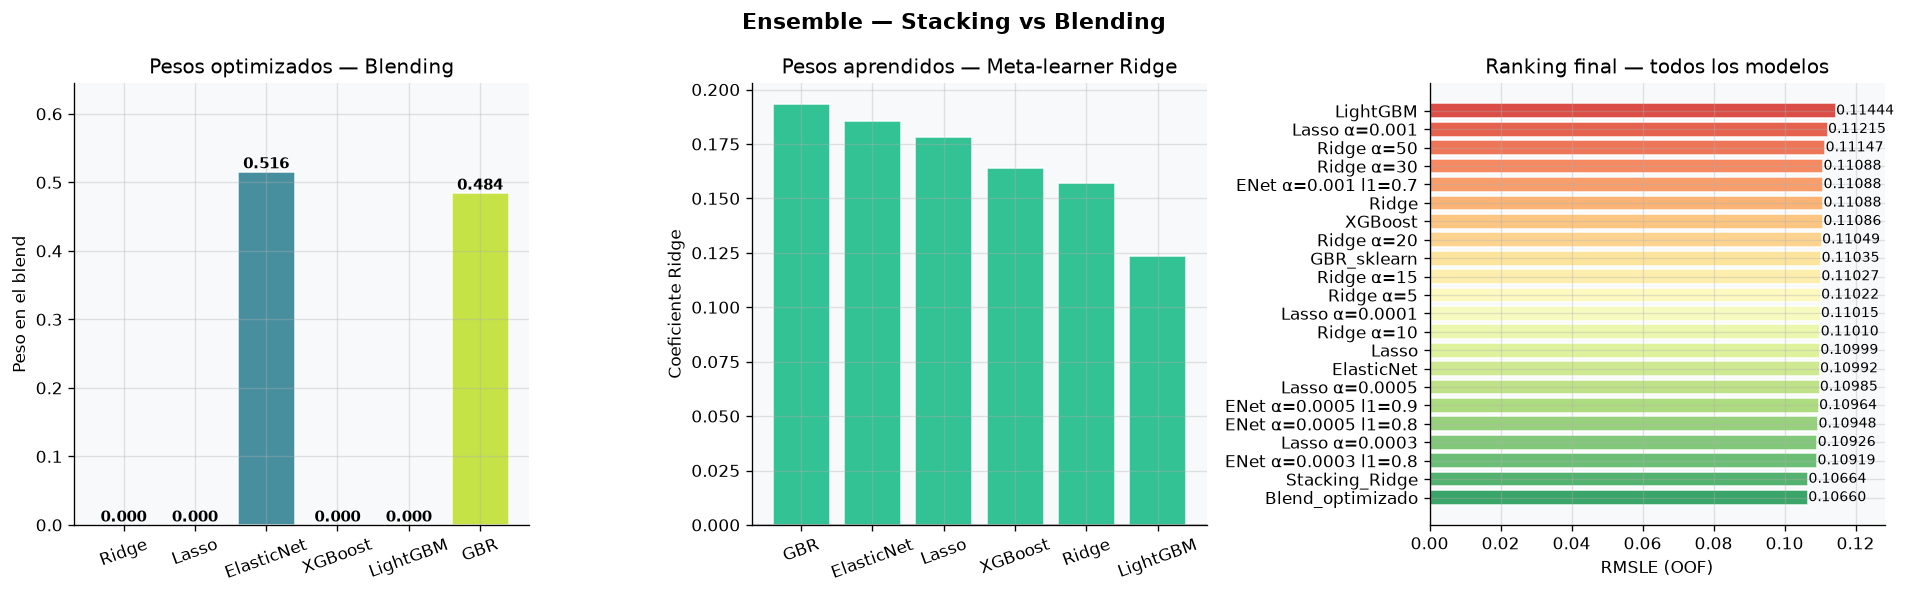

In [15]:
# ─── 9.2 VISUALIZAR PESOS DEL BLEND ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Ensemble — Stacking vs Blending', fontweight='bold', fontsize=13)

# Pesos del blend
ax = axes[0]
colors_w = plt.cm.viridis(np.linspace(0.1, 0.9, len(opt_weights)))
bars = ax.bar(meta_feature_names, opt_weights, color=colors_w, alpha=0.85, edgecolor='white')
for bar, w in zip(bars, opt_weights):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{w:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Peso en el blend')
ax.set_title('Pesos optimizados — Blending')
ax.set_ylim(0, max(opt_weights) * 1.25)
ax.tick_params(axis='x', rotation=20)

# Stacking coeficientes
ax = axes[1]
colors_s = [COLOR_SUCCESS if v > 0 else COLOR_DANGER for v in meta_coef_df['Peso']]
ax.bar(meta_coef_df['Modelo'], meta_coef_df['Peso'], color=colors_s, alpha=0.85, edgecolor='white')
ax.set_ylabel('Coeficiente Ridge')
ax.set_title('Pesos aprendidos — Meta-learner Ridge')
ax.axhline(0, color='black', linewidth=0.8)
ax.tick_params(axis='x', rotation=20)

# Ranking final de todos los modelos
ax = axes[2]
all_scores = pd.DataFrame([
    {'Modelo': k, 'RMSLE': v['mean']}
    for k, v in model_scores.items()
]).sort_values('RMSLE')
cmap_all = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(all_scores)))
bars2 = ax.barh(all_scores['Modelo'], all_scores['RMSLE'],
                color=cmap_all, alpha=0.85, edgecolor='white')
for bar, val in zip(bars2, all_scores['RMSLE']):
    ax.text(bar.get_width() + 0.0001, bar.get_y() + bar.get_height()/2,
            f'{val:.5f}', va='center', fontsize=8.5)
ax.set_xlabel('RMSLE (OOF)')
ax.set_title('Ranking final — todos los modelos')
ax.set_xlim(0, all_scores['RMSLE'].max() * 1.12)

plt.tight_layout()
plt.savefig('model_04_ensemble.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 10 · Diagnóstico de residuos
> Verificamos que el ensemble no tenga sesgos sistemáticos.

Mejor ensemble: Blend_optimizado  (RMSLE=0.10660)


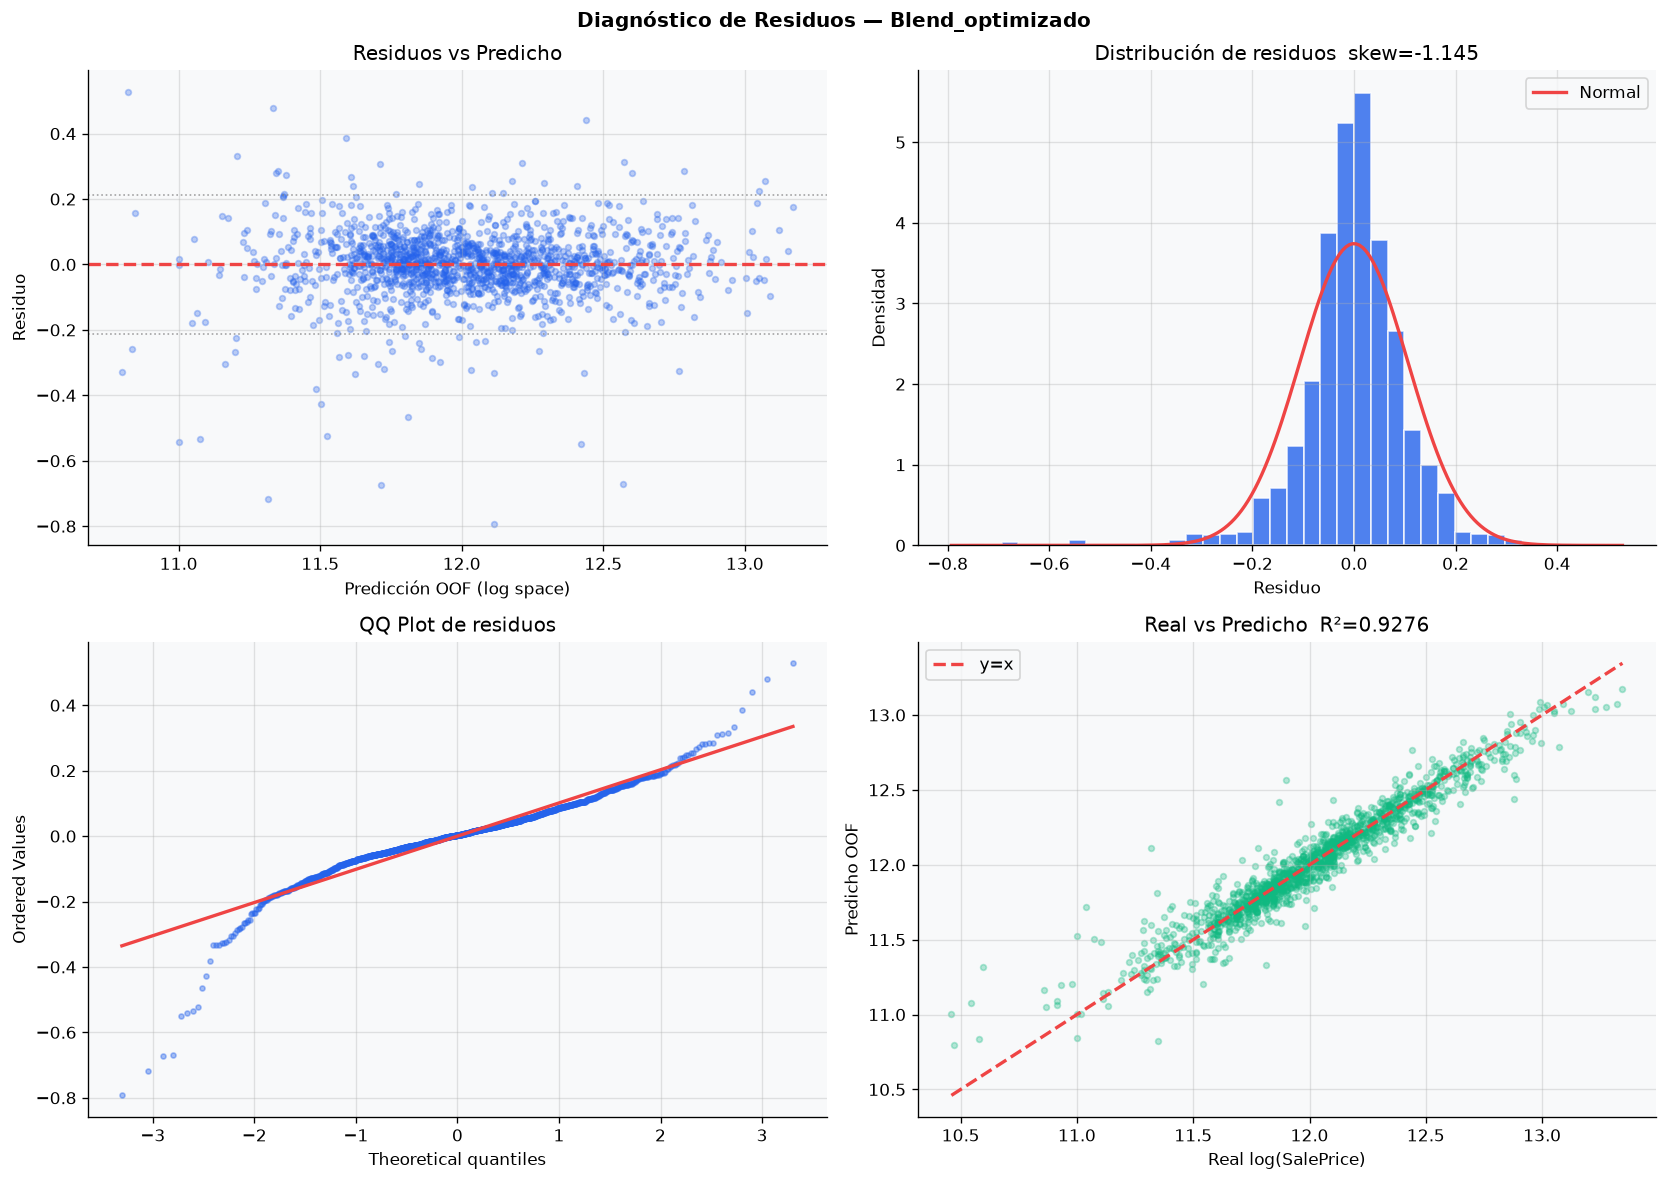


📊 Estadísticas de residuos:
   Media:    -0.00017  (ideal: ~0)
   Std:      0.10660
   |Max|:    0.79260
   Skewness: -1.1446  (ideal: ~0)
   R²:       0.92757


In [16]:
# ─── 10.1 ANÁLISIS DE RESIDUOS DEL MEJOR ENSEMBLE ──────────────────────────
# Elegir el mejor ensemble (menor RMSLE)
best_ensemble_name  = all_scores.iloc[0]['Modelo']
best_ensemble_rmsle = all_scores.iloc[0]['RMSLE']
print(f'Mejor ensemble: {best_ensemble_name}  (RMSLE={best_ensemble_rmsle:.5f})')

# Predicciones OOF del mejor
if best_ensemble_name == 'Blend_optimizado':
    best_oof = blend_oof
elif best_ensemble_name == 'Stacking_Ridge':
    best_oof = meta_ridge.predict(meta_train)
elif best_ensemble_name == 'XGBoost':
    best_oof = oof_xgb
elif best_ensemble_name == 'LightGBM':
    best_oof = oof_lgb
else:
    best_oof = blend_oof  # fallback

residuals = y.values - best_oof

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Diagnóstico de Residuos — {best_ensemble_name}', fontweight='bold')

# Residuos vs predicho
ax = axes[0, 0]
ax.scatter(best_oof, residuals, alpha=0.3, s=12, color=COLOR_MAIN)
ax.axhline(0, color=COLOR_DANGER, linewidth=2, linestyle='--')
ax.axhline( 2*residuals.std(), color='gray', linewidth=1, linestyle=':', alpha=0.7)
ax.axhline(-2*residuals.std(), color='gray', linewidth=1, linestyle=':', alpha=0.7)
ax.set_xlabel('Predicción OOF (log space)'); ax.set_ylabel('Residuo')
ax.set_title('Residuos vs Predicho')

# Distribución de residuos
ax = axes[0, 1]
ax.hist(residuals, bins=40, color=COLOR_MAIN, alpha=0.8, edgecolor='white', density=True)
xr = np.linspace(residuals.min(), residuals.max(), 200)
from scipy.stats import norm as _norm
ax.plot(xr, _norm.pdf(xr, residuals.mean(), residuals.std()),
        color=COLOR_DANGER, linewidth=2, label='Normal')
ax.set_xlabel('Residuo'); ax.set_ylabel('Densidad')
ax.set_title(f'Distribución de residuos  skew={stats.skew(residuals):.3f}')
ax.legend()

# QQ Plot
ax = axes[1, 0]
stats.probplot(residuals, dist='norm', plot=ax)
ax.get_lines()[0].set(color=COLOR_MAIN, markersize=3, alpha=0.4)
ax.get_lines()[1].set(color=COLOR_DANGER, linewidth=2)
ax.set_title('QQ Plot de residuos')

# Real vs predicho
ax = axes[1, 1]
ax.scatter(y.values, best_oof, alpha=0.3, s=12, color=COLOR_SUCCESS)
mn, mx = y.values.min(), y.values.max()
ax.plot([mn, mx], [mn, mx], color=COLOR_DANGER, linewidth=2, linestyle='--', label='y=x')
ax.set_xlabel('Real log(SalePrice)'); ax.set_ylabel('Predicho OOF')
ax.set_title(f'Real vs Predicho  R²={1 - residuals.var()/y.var():.4f}')
ax.legend()

plt.tight_layout()
plt.savefig('model_05_residuals.png', bbox_inches='tight', dpi=120)
plt.show()

print(f'\n📊 Estadísticas de residuos:')
print(f'   Media:    {residuals.mean():.5f}  (ideal: ~0)')
print(f'   Std:      {residuals.std():.5f}')
print(f'   |Max|:    {np.abs(residuals).max():.5f}')
print(f'   Skewness: {stats.skew(residuals):.4f}  (ideal: ~0)')
print(f'   R²:       {1 - residuals.var()/y.var():.5f}')

---
## 11 · Feature Importance — XGBoost y LightGBM

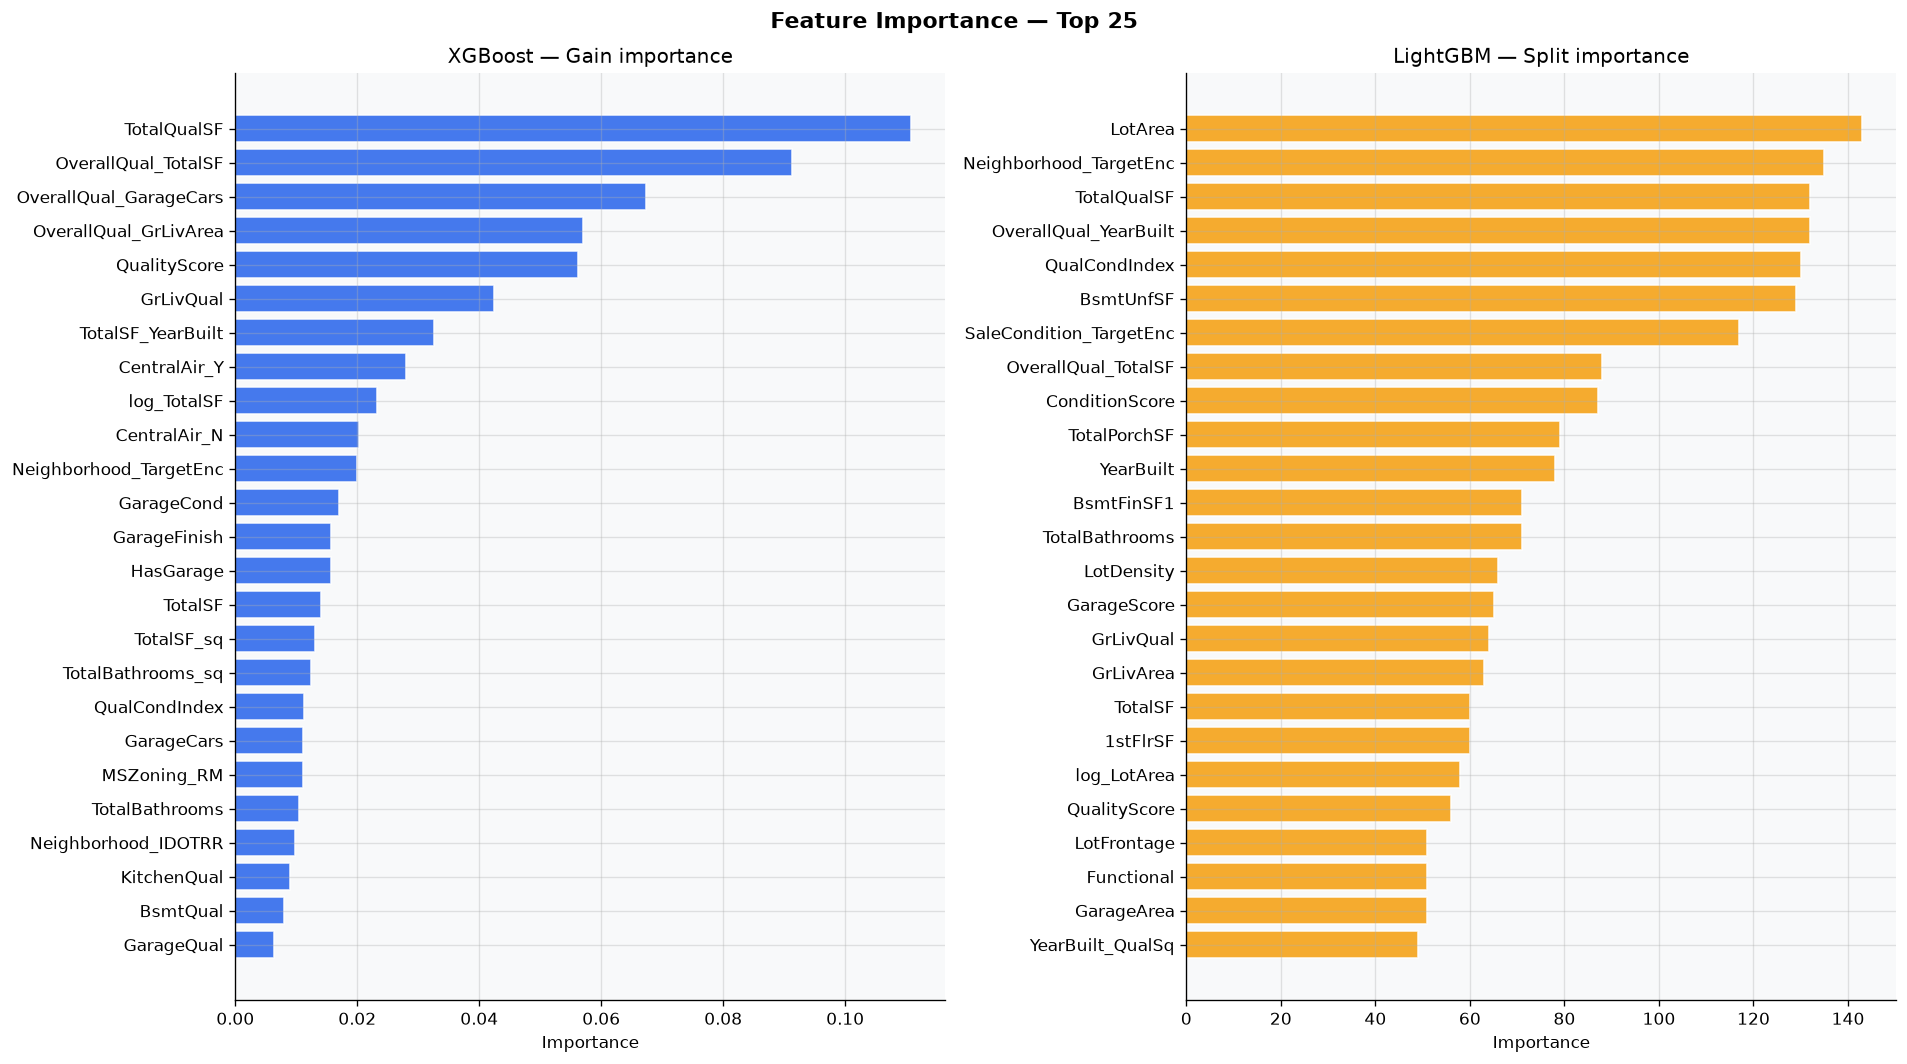


Features en Top-10 de AMBOS modelos (2):
   ✅ TotalQualSF
   ✅ OverallQual_TotalSF


In [17]:
# ─── 11.1 FEATURE IMPORTANCE COMPARADA ─────────────────────────────────────
# Entrenar modelos finales en todo el training set
xgb_final = xgb.XGBRegressor(**best_xgb_params)
lgb_final = lgb.LGBMRegressor(**best_lgb_params)

xgb_final.fit(X_train_raw, y)
lgb_final.fit(X_train_raw, y)

# Importancias
fi_xgb = pd.Series(xgb_final.feature_importances_, index=feature_names).sort_values(ascending=False)
fi_lgb = pd.Series(lgb_final.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fig.suptitle('Feature Importance — Top 25', fontweight='bold', fontsize=13)

ax = axes[0]
top25_xgb = fi_xgb.head(25)
ax.barh(top25_xgb.index[::-1], top25_xgb.values[::-1],
        color=COLOR_MAIN, alpha=0.85, edgecolor='white')
ax.set_title('XGBoost — Gain importance')
ax.set_xlabel('Importance')

ax = axes[1]
top25_lgb = fi_lgb.head(25)
ax.barh(top25_lgb.index[::-1], top25_lgb.values[::-1],
        color=COLOR_ACCENT, alpha=0.85, edgecolor='white')
ax.set_title('LightGBM — Split importance')
ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('model_06_feature_importance.png', bbox_inches='tight', dpi=120)
plt.show()

# Top 10 en común
top10_xgb = set(fi_xgb.head(10).index)
top10_lgb = set(fi_lgb.head(10).index)
common = top10_xgb & top10_lgb
print(f'\nFeatures en Top-10 de AMBOS modelos ({len(common)}):')
for f in common:
    print(f'   ✅ {f}')

---
## 12 · Submission final
> Generamos el CSV listo para subir a Kaggle.

In [18]:
# ─── 12.1 ELEGIR PREDICCIÓN FINAL ──────────────────────────────────────────
# Comparar stacking vs blending; elegir el de menor RMSLE OOF
print('Seleccionando predicción final...')
print(f'  Stacking RMSLE: {stacking_rmsle:.5f}')
print(f'  Blend    RMSLE: {blend_rmsle:.5f}')

if stacking_rmsle <= blend_rmsle:
    final_pred_log = stack_test_pred
    method_used    = 'Stacking_Ridge'
else:
    final_pred_log = blend_test
    method_used    = 'Blend_optimizado'

print(f'\n  Método seleccionado: {method_used}')

# Revertir log-transform: np.expm1 es la inversa de np.log1p
final_pred = np.expm1(final_pred_log)
final_pred = np.clip(final_pred, a_min=0, a_max=None)  # sin precios negativos

print(f'\nEstadísticas de las predicciones finales (en $):')
print(f'  Min:    ${final_pred.min():>12,.0f}')
print(f'  Media:  ${final_pred.mean():>12,.0f}')
print(f'  Mediana:${np.median(final_pred):>12,.0f}')
print(f'  Max:    ${final_pred.max():>12,.0f}')

Seleccionando predicción final...
  Stacking RMSLE: 0.10664
  Blend    RMSLE: 0.10660

  Método seleccionado: Blend_optimizado

Estadísticas de las predicciones finales (en $):
  Min:    $      39,063
  Media:  $     178,347
  Mediana:$     156,384
  Max:    $     776,323


✅ submission.csv generado correctamente
   Filas: 1459
   Columnas: ['Id', 'SalePrice']

  Id    SalePrice
1461 120231.15574
1462 157542.02268
1463 180357.26626
1464 193669.25282
1465 193925.85928
1466 173039.78441
1467 177773.10383
1468 165296.95371
1469 188947.24738
1470 119607.74880


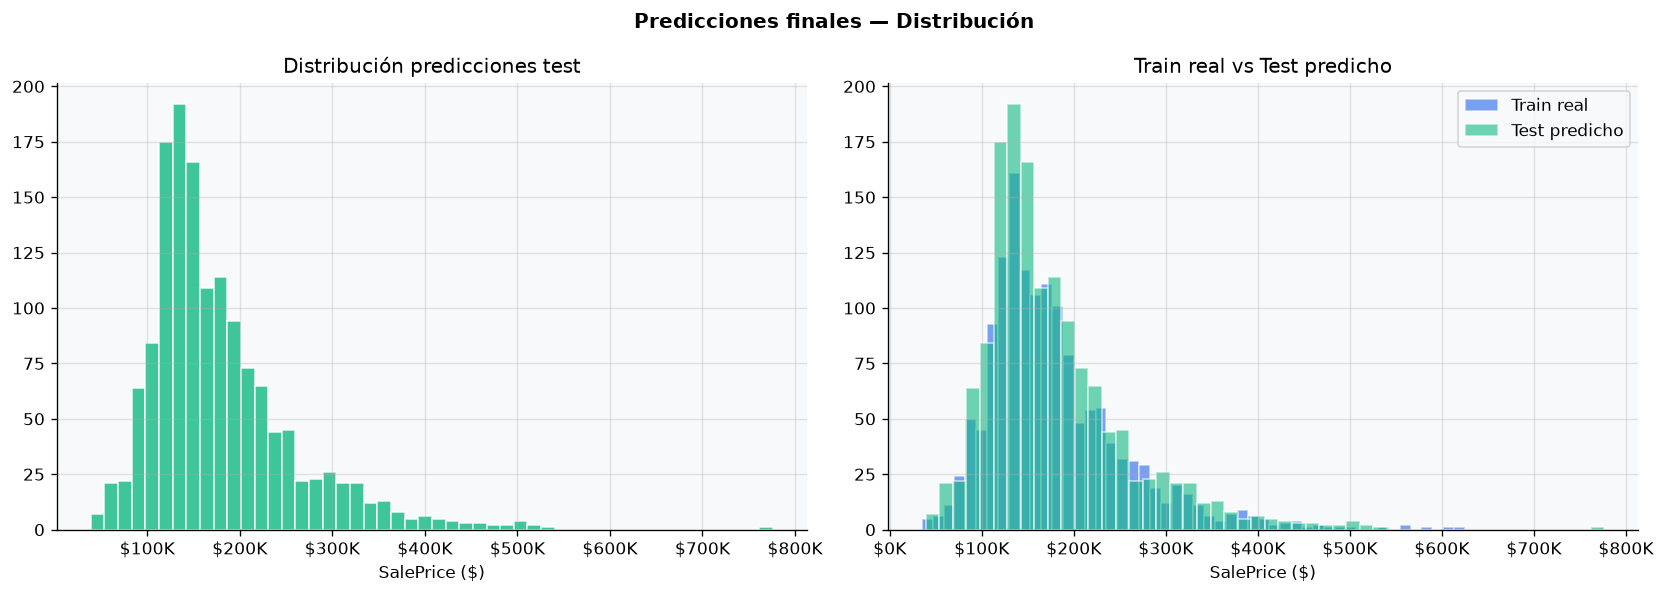

In [19]:
# ─── 12.2 CREAR ARCHIVO DE SUBMISSION ──────────────────────────────────────
submission = pd.DataFrame({
    'Id'       : test_ids.values,
    'SalePrice': final_pred
})
submission.to_csv('submission.csv', index=False)

# Verificación
assert len(submission) == len(test_ids), '❌ Número de predicciones incorrecto'
assert submission['SalePrice'].isnull().sum() == 0, '❌ Hay nulos en las predicciones'
assert (submission['SalePrice'] > 0).all(), '❌ Hay precios no positivos'

print('✅ submission.csv generado correctamente')
print(f'   Filas: {len(submission)}')
print(f'   Columnas: {list(submission.columns)}')
print()
print(submission.head(10).to_string(index=False))

# Visualizar distribución de predicciones vs distribución real de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Predicciones finales — Distribución', fontweight='bold')

ax = axes[0]
ax.hist(final_pred, bins=50, color=COLOR_SUCCESS, alpha=0.8, edgecolor='white', label='Predicciones test')
ax.set_xlabel('SalePrice ($)')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Distribución predicciones test')

ax = axes[1]
train_prices = np.expm1(y.values)
ax.hist(train_prices, bins=50, color=COLOR_MAIN, alpha=0.6, edgecolor='white', label='Train real')
ax.hist(final_pred,   bins=50, color=COLOR_SUCCESS, alpha=0.6, edgecolor='white', label='Test predicho')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_xlabel('SalePrice ($)')
ax.set_title('Train real vs Test predicho')
ax.legend()

plt.tight_layout()
plt.savefig('model_07_submission_dist.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 13 · Guardado de modelos y resumen ejecutivo

In [20]:
# ─── 13.1 GUARDAR MODELOS ENTRENADOS ────────────────────────────────────────
# Reentrenar modelos base en TODO el training (sin CV) para producción
ridge_final = Ridge(alpha=best_ridge_alpha).fit(X_train_scaled, y)
lasso_final = Lasso(alpha=best_lasso_alpha, max_iter=15000).fit(X_train_scaled, y)
enet_final  = ElasticNet(alpha=best_enet[0], l1_ratio=best_enet[1], max_iter=15000).fit(X_train_scaled, y)

joblib.dump(ridge_final,  'model_ridge.pkl')
joblib.dump(lasso_final,  'model_lasso.pkl')
joblib.dump(enet_final,   'model_enet.pkl')
joblib.dump(xgb_final,    'model_xgb.pkl')
joblib.dump(lgb_final,    'model_lgb.pkl')
joblib.dump(meta_ridge,   'model_meta_ridge.pkl')
joblib.dump(opt_weights,  'blend_weights.pkl')
np.save('oof_predictions.npy', meta_train)
np.save('test_predictions_base.npy', meta_test)

# Guardar mejores params de Optuna
import json
with open('best_params_xgb.json', 'w') as f:
    json.dump(study_xgb.best_params, f, indent=2)
with open('best_params_lgb.json', 'w') as f:
    json.dump(study_lgb.best_params, f, indent=2)

print('✅ Modelos guardados:')
artefacts = {
    'model_ridge.pkl'         : f'Ridge (α={best_ridge_alpha})',
    'model_lasso.pkl'         : f'Lasso (α={best_lasso_alpha})',
    'model_enet.pkl'          : f'ElasticNet (α={best_enet[0]}, l1={best_enet[1]})',
    'model_xgb.pkl'           : 'XGBoost (Optuna tuned)',
    'model_lgb.pkl'           : 'LightGBM (Optuna tuned)',
    'model_meta_ridge.pkl'    : f'Meta-learner Ridge (α={best_meta_alpha})',
    'blend_weights.pkl'       : 'Pesos blend optimizados',
    'best_params_xgb.json'    : 'Mejores params XGBoost',
    'best_params_lgb.json'    : 'Mejores params LightGBM',
    'oof_predictions.npy'     : 'OOF predictions (meta-features)',
    'submission.csv'          : 'Submission final para Kaggle',
}
for fname, desc in artefacts.items():
    if os.path.exists(fname):
        size = os.path.getsize(fname) / 1024
        print(f'   📄 {fname:<30} {size:7.1f} KB  — {desc}')

✅ Modelos guardados:
   📄 model_ridge.pkl                    2.8 KB  — Ridge (α=10)
   📄 model_lasso.pkl                    2.9 KB  — Lasso (α=0.0003)
   📄 model_enet.pkl                     2.9 KB  — ElasticNet (α=0.0003, l1=0.8)
   📄 model_xgb.pkl                   2330.2 KB  — XGBoost (Optuna tuned)
   📄 model_lgb.pkl                    519.0 KB  — LightGBM (Optuna tuned)
   📄 model_meta_ridge.pkl               0.6 KB  — Meta-learner Ridge (α=5.0)
   📄 blend_weights.pkl                  0.3 KB  — Pesos blend optimizados
   📄 best_params_xgb.json               0.3 KB  — Mejores params XGBoost
   📄 best_params_lgb.json               0.3 KB  — Mejores params LightGBM
   📄 oof_predictions.npy               68.4 KB  — OOF predictions (meta-features)
   📄 submission.csv                    35.1 KB  — Submission final para Kaggle


In [21]:
# ─── 13.2 RESUMEN EJECUTIVO FINAL ───────────────────────────────────────────
print()
print('═' * 70)
print('  RESUMEN EJECUTIVO — MODELADO AVANZADO + ENSEMBLE')
print('═' * 70)

all_scores_final = pd.DataFrame([
    {'Modelo': k, 'OOF_RMSLE': v['mean']}
    for k, v in model_scores.items()
]).sort_values('OOF_RMSLE')

print(f'''
📊 MODELOS ENTRENADOS Y RESULTADOS OOF (10-fold CV)
''')
for _, row in all_scores_final.iterrows():
    bar_len = int((0.20 - row['OOF_RMSLE']) * 1000)
    bar = '█' * max(0, bar_len)
    marker = '⭐' if row['Modelo'] == best_ensemble_name else '  '
    print(f'  {marker} {row["Modelo"]:<22} RMSLE = {row["OOF_RMSLE"]:.5f}  {bar}')

best_rmsle = all_scores_final.iloc[0]['OOF_RMSLE']
best_model = all_scores_final.iloc[0]['Modelo']

print(f'''
🏆 MEJOR MODELO: {best_model}
   OOF RMSLE: {best_rmsle:.5f}
   Método submission: {method_used}

📐 PIPELINE COMPLETO
   01_EDA.ipynb               → entender el dataset
   02_FeatureEngineering.ipynb → +15 features nuevas (FE)
   03_Preprocessing_Final.ipynb → Versión A (scaled) + Versión B (raw)
   04_Models.ipynb             → este notebook

📤 SUBMISSION
   Archivo: submission.csv
   Filas:   {len(submission)}
   Rango:   ${final_pred.min():,.0f} — ${final_pred.max():,.0f}

💡 PRÓXIMOS PASOS (para mejorar aún más)
   1. Subir submission.csv a Kaggle y comparar CV vs Public LB
   2. Si CV < LB: hay overfitting → reducir n_estimators o aumentar alpha
   3. Si CV > LB: problema de leakage → revisar target encoding
   4. Probar CatBoost como 4to modelo del ensemble
   5. Aumentar n_trials de Optuna a 100+ para mejor tuning
   6. Pseudo-labeling con predicciones de test seguras
''')
print('═' * 70)


══════════════════════════════════════════════════════════════════════
  RESUMEN EJECUTIVO — MODELADO AVANZADO + ENSEMBLE
══════════════════════════════════════════════════════════════════════

📊 MODELOS ENTRENADOS Y RESULTADOS OOF (10-fold CV)

  ⭐ Blend_optimizado       RMSLE = 0.10660  █████████████████████████████████████████████████████████████████████████████████████████████
     Stacking_Ridge         RMSLE = 0.10664  █████████████████████████████████████████████████████████████████████████████████████████████
     ENet α=0.0003 l1=0.8   RMSLE = 0.10919  ██████████████████████████████████████████████████████████████████████████████████████████
     Lasso α=0.0003         RMSLE = 0.10926  ██████████████████████████████████████████████████████████████████████████████████████████
     ENet α=0.0005 l1=0.8   RMSLE = 0.10948  ██████████████████████████████████████████████████████████████████████████████████████████
     ENet α=0.0005 l1=0.9   RMSLE = 0.10964  ███████████████████████